# Dataset and model sanity checks

Run these checks independently of exploration. Training here intentionally updates only a tiny temporary model. These are learning checks, not baseline results. Saved figures below are historical outputs; rerunning will produce new outputs.

In [ ]:
from pathlib import Path
import sys

project_dir = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / "voc_detection").is_dir() and (path / "configs").is_dir()
)
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))


In [ ]:
from voc_detection.project import load_config, make_loader
config = load_config()
dataset_dir = project_dir / config["dataset_dir"]


In [33]:
import voc_detection.dataset as dataset
from voc_detection.dataset import VOCDetectionDataset

training_dataset = VOCDetectionDataset(
    dataset_dir=dataset_dir,
    split_file=project_dir / "splits/train.txt",
)

print("Training examples:", len(training_dataset))


Training examples: 4573


In [34]:
image, target = training_dataset[0]

print("Image shape:", image.shape)
print("Pixel range:", image.min().item(), image.max().item())
print("Boxes:", target["boxes"])
print("Labels:", target["labels"])
print("Difficult:", target["difficult"])


Image shape: torch.Size([3, 442, 500])
Pixel range: 0.0 1.0
Boxes: tensor([[ 52.,  86., 471., 420.],
        [157.,  43., 289., 167.]])
Labels: tensor([13, 15])
Difficult: tensor([False, False])


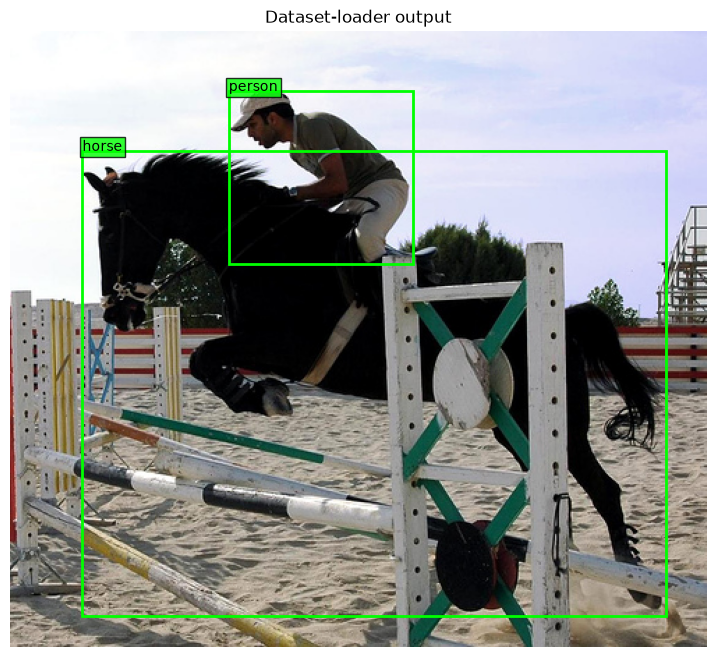

In [35]:
from voc_detection.dataset import VOC_CLASSES
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt

image, target = training_dataset[0]

display_image = image.permute(1, 2, 0)

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(
    display_image,
    extent=(0, image.shape[2], image.shape[1], 0),
)

for box, label, difficult in zip(
    target["boxes"],
    target["labels"],
    target["difficult"],
):
    xmin, ymin, xmax, ymax = box.tolist()
    category = VOC_CLASSES[label.item() - 1]

    rectangle = Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        fill=False,
        edgecolor="lime",
        linewidth=2,
        linestyle="--" if difficult.item() else "-",
    )
    ax.add_patch(rectangle)

    ax.text(
        xmin,
        ymin,
        category,
        color="black",
        bbox={"facecolor": "lime", "alpha": 0.8, "pad": 2},
    )

ax.set_title("Dataset-loader output")
ax.axis("off")
plt.show()


In [36]:
import importlib
import voc_detection.dataset as dataset

importlib.reload(dataset)


<module 'dataset' from '/Users/faikbairamov/Documents/workspace/pascal-voc-object-detection/dataset.py'>

In [37]:
import torch
from torch.utils.data import DataLoader

training_loader = DataLoader(
    training_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    collate_fn=dataset.detection_collate_fn,
    generator=torch.Generator().manual_seed(42),
)


In [38]:
images, targets = next(iter(training_loader))

print("Images in batch:", len(images))

for index, (image, target) in enumerate(zip(images, targets)):
    print(
        f"Example {index}:",
        "image shape =", tuple(image.shape),
        "boxes shape =", tuple(target["boxes"].shape),
        "labels shape =", tuple(target["labels"].shape),
    )


Images in batch: 2
Example 0: image shape = (3, 500, 375) boxes shape = (3, 4) labels shape = (3,)
Example 1: image shape = (3, 499, 500) boxes shape = (7, 4) labels shape = (7,)


In [39]:
validation_dataset = dataset.VOCDetectionDataset(
    dataset_dir=dataset_dir,
    split_file=project_dir / "splits/dev.txt",
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    collate_fn=dataset.detection_collate_fn,
)

print("Validation examples:", len(validation_dataset))

images, targets = next(iter(validation_loader))
print("Images in batch:", len(images))


Validation examples: 1144
Images in batch: 2


In [40]:
import torch

def check_dataset(data):
    for index in range(len(data)):
        image, target = data[index]

        boxes = target["boxes"]
        labels = target["labels"]

        assert image.ndim == 3 and image.shape[0] == 3, index
        assert torch.isfinite(image).all(), index
        assert 0 <= image.min() and image.max() <= 1, index

        assert boxes.ndim == 2 and boxes.shape[1] == 4, index
        assert torch.isfinite(boxes).all(), index
        assert labels.shape == (len(boxes),), index
        assert target["difficult"].shape == labels.shape, index
        assert ((labels >= 1) & (labels <= 20)).all(), index

        height, width = image.shape[1:]

        assert (boxes[:, 0] >= 0).all(), index
        assert (boxes[:, 1] >= 0).all(), index
        assert (boxes[:, 2] <= width).all(), index
        assert (boxes[:, 3] <= height).all(), index
        assert (boxes[:, 2] > boxes[:, 0]).all(), index
        assert (boxes[:, 3] > boxes[:, 1]).all(), index

    print(f"Passed: {len(data)} images")

check_dataset(training_dataset)
check_dataset(validation_dataset)


Passed: 4573 images
Passed: 1144 images


In [41]:
from voc_detection.model import create_model

model = create_model()

print("Output classes:", model.roi_heads.box_predictor.cls_score.out_features)


Output classes: 21


In [42]:
import torch

device = torch.device("cpu")
model = model.to(device)
model.train()

images, targets = next(iter(training_loader))

images = [image.to(device) for image in images]

model_targets = [
    {
        "boxes": target["boxes"].to(device),
        "labels": target["labels"].to(device),
    }
    for target in targets
]

losses = model(images, model_targets)
total_loss = sum(losses.values())

assert torch.isfinite(total_loss), "The loss is not finite."

for name, value in losses.items():
    print(f"{name}: {value.detach().item():.4f}")

print(f"Total loss: {total_loss.detach().item():.4f}")


loss_classifier: 2.8769
loss_box_reg: 0.6970
loss_objectness: 0.0545
loss_rpn_box_reg: 0.0365
Total loss: 3.6648


In [43]:
optimizer = torch.optim.SGD(
    [parameter for parameter in model.parameters() if parameter.requires_grad],
    lr=0.001,
    momentum=0.9,
    weight_decay=0.0005,
)

optimizer.zero_grad()
total_loss.backward()

for name, parameter in model.named_parameters():
    if parameter.grad is not None:
        assert torch.isfinite(parameter.grad).all(), (
            f"Invalid gradient in {name}"
        )

optimizer.step()

print("One training step completed.")


One training step completed.


In [44]:
model.train()
loss_history = []

for step in range(80):
    optimizer.zero_grad()

    losses = model(images, model_targets)
    total_loss = sum(losses.values())

    assert torch.isfinite(total_loss), "Non-finite loss encountered."

    total_loss.backward()
    optimizer.step()

    loss_value = total_loss.detach().item()
    loss_history.append(loss_value)

    if step == 0 or (step + 1) % 5 == 0:
        print(f"Step {step + 1:02d} | Loss: {loss_value:.4f}")


Step 01 | Loss: 3.5986
Step 05 | Loss: 2.6983
Step 10 | Loss: 2.0929
Step 15 | Loss: 1.8428
Step 20 | Loss: 1.6733
Step 25 | Loss: 1.6034
Step 30 | Loss: 1.4144
Step 35 | Loss: 1.3002
Step 40 | Loss: 1.1613
Step 45 | Loss: 1.0500
Step 50 | Loss: 0.9684
Step 55 | Loss: 0.8798
Step 60 | Loss: 0.8210
Step 65 | Loss: 0.7648
Step 70 | Loss: 0.7204
Step 75 | Loss: 0.6964
Step 80 | Loss: 0.6201


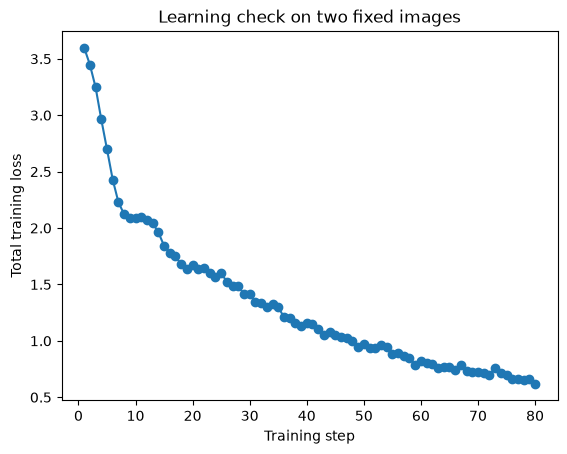

In [45]:
plt.plot(range(1, len(loss_history) + 1), loss_history, marker="o")
plt.xlabel("Training step")
plt.ylabel("Total training loss")
plt.title("Learning check on two fixed images")
plt.show()


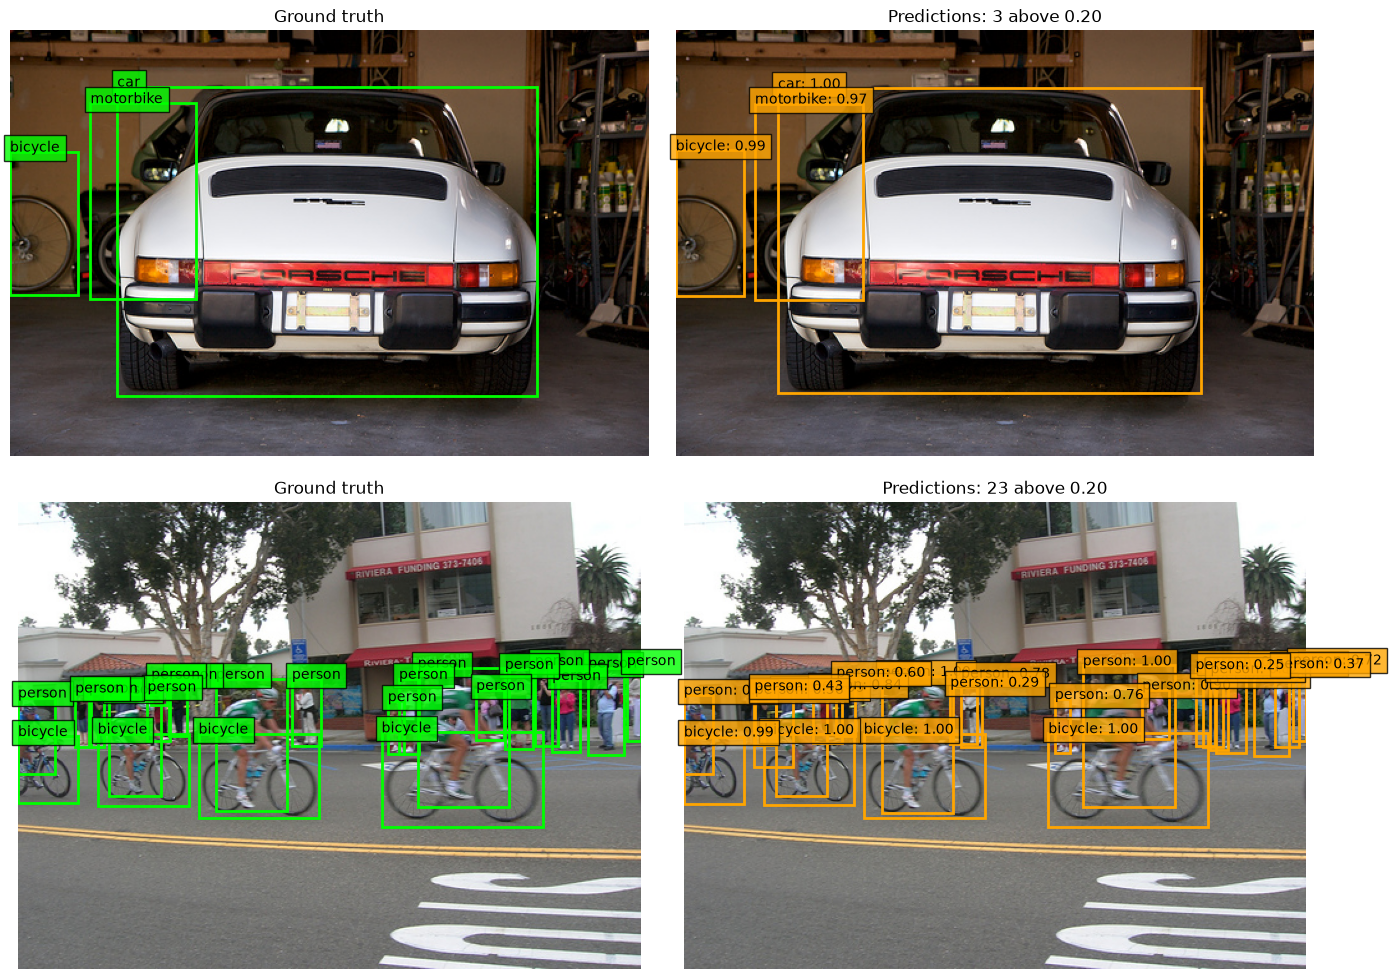

In [46]:
from voc_detection.dataset import VOC_CLASSES
from matplotlib.patches import Rectangle

model.eval()

with torch.no_grad():
    predictions = model(images)

threshold = 0.20

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for row, (image, target, prediction) in enumerate(
    zip(images, model_targets, predictions)
):
    photo = image.detach().cpu().permute(1, 2, 0)
    height, width = photo.shape[:2]

    for ax in axes[row]:
        ax.imshow(photo, extent=(0, width, height, 0))
        ax.axis("off")

    for box, label in zip(target["boxes"], target["labels"]):
        xmin, ymin, xmax, ymax = box.detach().cpu().tolist()
        category = VOC_CLASSES[label.item() - 1]

        axes[row, 0].add_patch(
            Rectangle(
                (xmin, ymin),
                xmax - xmin,
                ymax - ymin,
                fill=False,
                edgecolor="lime",
                linewidth=2,
            )
        )
        axes[row, 0].text(
            xmin, ymin, category,
            bbox={"facecolor": "lime", "alpha": 0.8},
        )

    count = 0

    for box, label, score in zip(
        prediction["boxes"],
        prediction["labels"],
        prediction["scores"],
    ):
        if score.item() < threshold:
            continue

        xmin, ymin, xmax, ymax = box.detach().cpu().tolist()
        category = VOC_CLASSES[label.item() - 1]

        axes[row, 1].add_patch(
            Rectangle(
                (xmin, ymin),
                xmax - xmin,
                ymax - ymin,
                fill=False,
                edgecolor="orange",
                linewidth=2,
            )
        )
        axes[row, 1].text(
            xmin, ymin, f"{category}: {score.item():.2f}",
            bbox={"facecolor": "orange", "alpha": 0.8},
        )
        count += 1

    axes[row, 0].set_title("Ground truth")
    axes[row, 1].set_title(
        f"Predictions: {count} above {threshold:.2f}"
    )

plt.tight_layout()
plt.show()
